Tehtävä 13
Lisää tehtävän 12 signaaliin 5cos(50t).

a) Tutki muutosta tehospektrissä käyttäen edelleen näytteenottoväliä 0,1 s.

b) Selitä, miksi uusi huippu ei näy odotetulla taajuudella.

c) Valitse riittävä näytteenottotaajuus ja tarkista tulos muodostamalla signaali ja laskemalla Fourier-muunnos uudelleen.


7.957747154594767


(np.float64(0.0), np.float64(10.0), np.float64(-13.0), np.float64(13.0))

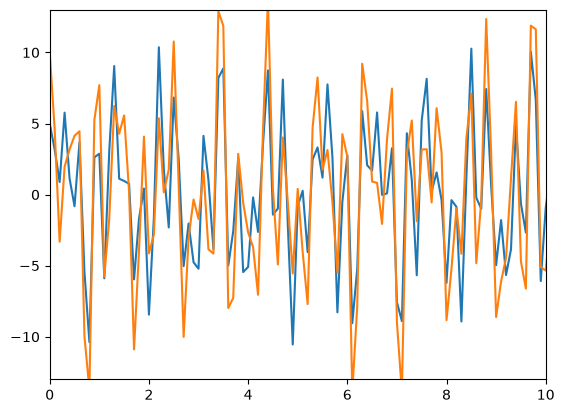

In [22]:
import numpy as np
import matplotlib.pyplot as plt

#Lisää tehtävän 12 signaaliin 5cos(50t).

dt= 0.1
t = np.arange(0, 100, dt) 
f1 = 4*np.sin(6*t)
f2 = 3*np.sin(15*t)
f3 = 5*np.cos(20*t)
f4 = 5*np.cos(50*t)
noisy_signal1 = f1 + f2 + f3        #alkuperäinen funktio
noisy_signal2 = f1 + f2 + f3 + f4   #alkuperäinen + f4
f_f4 = 50/(2*np.pi)                 #f4 taajuus
print(f_f4)
plt.plot(t, noisy_signal1)
plt.plot(t, noisy_signal2)
plt.axis([0,10,-13,13])



1000


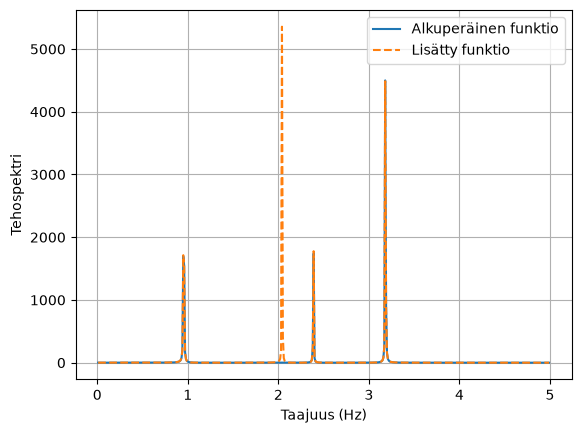

In [ ]:
#a) Tutki muutosta tehospektrissä käyttäen edelleen näytteenottoväliä 0,1 s.

f1 = noisy_signal1
f2 = noisy_signal2
N = len(f1)

#fourier
fourier1 = np.fft.fft(f1, N)
fourier2 = np.fft.fft(f2, N)

#tehospektri
psd1 = fourier1*np.conj(fourier1)/N
psd2 = fourier2*np.conj(fourier2)/N

#freq = 1/(dt*N)*np.arange(N) #Taajuudet
freq = np.fft.fftfreq(N,dt)
L = np.arange(1, np.floor(N/2), dtype='int') #Määritellään ne tehospektrin arvot, joita käytetään
PSD1 = np.array([freq[L], psd1[L].real]) #Taajuudet ja tehospektrin arvot
PSD2 = np.array([freq[L], psd2[L].real]) #Taajuudet ja tehospektrin arvot

plt.plot(PSD1[0,:], PSD1[1,:], label="Alkuperäinen funktio")
plt.plot(PSD2[0,:], PSD2[1,:], "--", label="Lisätty funktio")
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
plt.legend()
plt.grid()
plt.show()



b) Selitä, miksi uusi huippu ei näy odotetulla taajuudella.

Lisätyn komponentin taajuus on noin 7,96 Hz, mikä ylittää 5 Hz:n Nyquistin taajuuden. Siksi komponentti aliasoituu, ja spektrissä näkyy huippu noin 2,04 Hz:n kohdalla.

Lisätyn komponentin laskettu taajuus: 7.958 Hz
FFT:stä löydetty huippu: 7.967 Hz


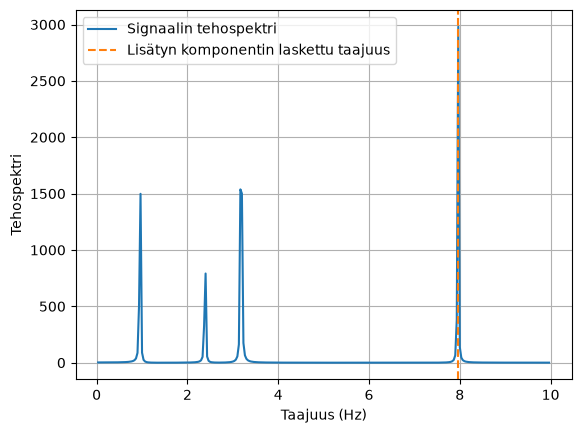

In [32]:
# Valitse riittävä näytteenottotaajuus ja tarkista tulos muodostamalla signaali 
# ja laskemalla Fourier-muunnos uudelleen.
#f_f4 = 50/(2*np.pi)                 #f4 taajuus


tarkistus_fs = 20.0
tarkistus_dt = 1 / tarkistus_fs
tarkistus_t = np.arange(0, 30, tarkistus_dt)

tarkistus_f4_hz = 50 / (2 * np.pi)
tarkistus_signaali = (
    4 * np.sin(6 * tarkistus_t)
    + 3 * np.sin(15 * tarkistus_t)
    + 5 * np.cos(20 * tarkistus_t)
    + 5 * np.cos(50 * tarkistus_t)
)

tarkistus_N = len(tarkistus_signaali)
tarkistus_fourier = np.fft.fft(tarkistus_signaali)
tarkistus_freq = np.fft.fftfreq(tarkistus_N, d=tarkistus_dt)
tarkistus_psd = np.abs(tarkistus_fourier)**2 / tarkistus_N

# Valitaan kuvaajaan positiiviset taajuudet ja niitä vastaavat spektriarvot.
tarkistus_positiiviset = tarkistus_freq > 0

# Muut kolme komponenttia ovat alle 5 Hz:n.
tarkistus_yli_5_hz = tarkistus_freq > 5
tarkistus_huippu = tarkistus_freq[tarkistus_yli_5_hz][
    np.argmax(tarkistus_psd[tarkistus_yli_5_hz])
]

print(f"Lisätyn komponentin laskettu taajuus: {tarkistus_f4_hz:.3f} Hz")
print(f"FFT:stä löydetty huippu: {tarkistus_huippu:.3f} Hz")

plt.figure()
plt.plot(
    tarkistus_freq[tarkistus_positiiviset],
    tarkistus_psd[tarkistus_positiiviset],
    label="Signaalin tehospektri",
)
plt.axvline(
    tarkistus_f4_hz,
    color="tab:orange",
    linestyle="--",
    label="Lisätyn komponentin laskettu taajuus",
)
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
plt.legend()
plt.grid()
plt.show()
